# **Nama: Andika Dinata**
# **NIM: 123140096**


In [8]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = False

print("numpy   :", np.__version__)
print("librosa :", librosa.__version__)

numpy   : 2.1.3
librosa : 0.11.0


## 1. Soal 1 - Raw Waveform dan Teorema Sampling

Sinyal audio mentah adalah deretan sampel amplitudo terhadap waktu. Teorema Nyquist–Shannon mensyaratkan laju pencuplikan memenuhi fs > 2 fmax agar sinyal asli dapat dire-konstruksi tanpa aliasing

### a. Bangkitkan nada murni 440 Hz (nada A4) berdurasi 2 detik dengan sampling rate fs = 22050 Hz. Plot 500 sampel pertamanya.

Laju pencuplikan (fs)   : 22050 Hz
Durasi sinyal           : 2.0 detik
Jumlah sampel dihasilkan: 44100


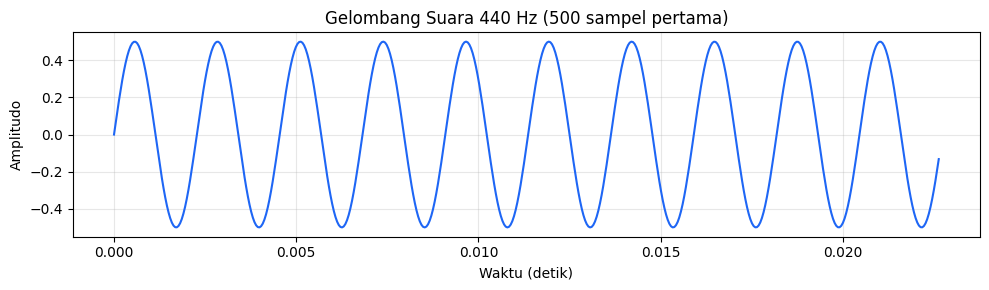

In [9]:
SR, DURASI = 22050, 2.0
n_sampel = int(SR * DURASI)
t = np.linspace(0, DURASI, n_sampel, endpoint=False)

freq1 = 440.0
sinyal = 0.5 * np.sin(2 * np.pi * freq1 * t)

print(f"Laju pencuplikan (fs)   : {SR} Hz")
print(f"Durasi sinyal           : {DURASI} detik")
print(f"Jumlah sampel dihasilkan: {n_sampel}")

plt.figure(figsize=(10, 3))
plt.plot(t[:500], sinyal[:500], color="#1e66f5")
plt.xlabel("Waktu (detik)")
plt.ylabel("Amplitudo")
plt.title("Gelombang Suara 440 Hz (500 sampel pertama)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### b. Campurkan nada 440 Hz dan 880 Hz, lalu turunkan sampling rate menjadi 1000 Hz untuk mensimulasikan aliasing. Plot hasilnya.

Nyquist pada fs=22050 Hz  : 11025.0 Hz  (440 Hz & 880 Hz aman)
Nyquist pada fs=1000 Hz  : 500.0 Hz
880 Hz melebihi Nyquist rendah, muncul sebagai frekuensi semu (alias) sebesar |880-1000| = 120.0 Hz


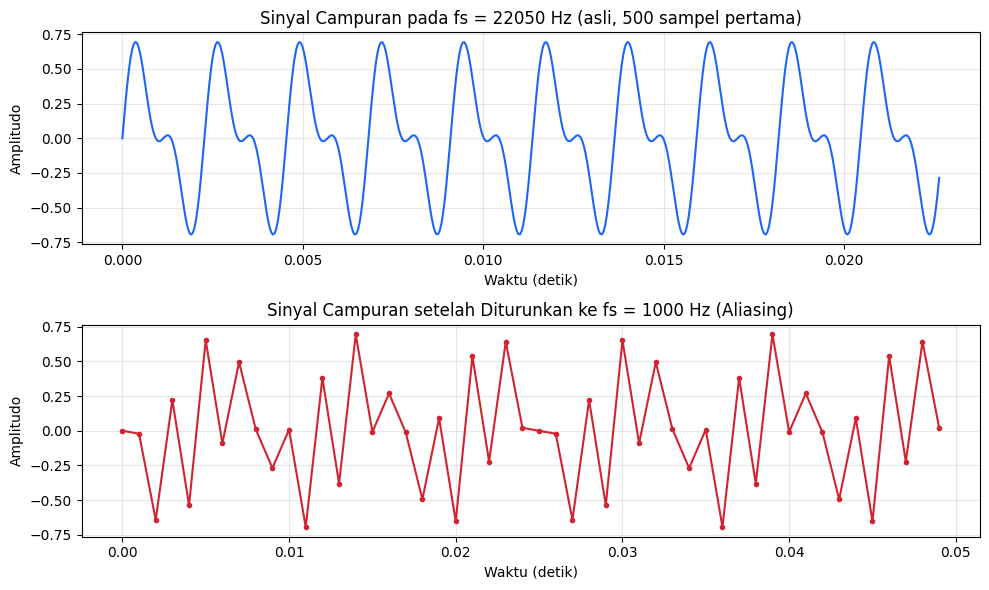

In [10]:
freq2 = 880.0
sinyal_campuran = 0.5 * np.sin(2 * np.pi * freq1 * t) + 0.3 * np.sin(2 * np.pi * freq2 * t)

# Simulasi aliasing: bangkitkan ulang sinyal yang sama pada fs jauh lebih rendah
fs_rendah = 1000
n_rendah = int(fs_rendah * DURASI)
t_rendah = np.linspace(0, DURASI, n_rendah, endpoint=False)
sinyal_campuran_alias = 0.5 * np.sin(2 * np.pi * freq1 * t_rendah) + 0.3 * np.sin(2 * np.pi * freq2 * t_rendah)

nyquist_asli = SR / 2
nyquist_rendah = fs_rendah / 2
freq_alias_880 = abs(freq2 - fs_rendah)

print(f"Nyquist pada fs={SR} Hz  : {nyquist_asli} Hz  (440 Hz & 880 Hz aman)")
print(f"Nyquist pada fs={fs_rendah} Hz  : {nyquist_rendah} Hz")
print(f"880 Hz melebihi Nyquist rendah, muncul sebagai frekuensi semu (alias) sebesar |880-1000| = {freq_alias_880} Hz")

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].plot(t[:500], sinyal_campuran[:500], color="#1e66f5")
axes[0].set_title(f"Sinyal Campuran pada fs = {SR} Hz (asli, 500 sampel pertama)")
axes[0].set_xlabel("Waktu (detik)")
axes[0].set_ylabel("Amplitudo")
axes[0].grid(alpha=0.3)

axes[1].plot(t_rendah[:50], sinyal_campuran_alias[:50], color="#d1242f", marker="o", markersize=3)
axes[1].set_title(f"Sinyal Campuran setelah Diturunkan ke fs = {fs_rendah} Hz (Aliasing)")
axes[1].set_xlabel("Waktu (detik)")
axes[1].set_ylabel("Amplitudo")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### c. Analisis

**Mengapa sinyal berdurasi 2 detik pada fs = 22050 Hz menghasilkan 44100 sampel?**

Jumlah sampel dihitung dari perkalian antara laju pencuplikan dan durasi sinyal, yaitu n = fs x durasi = 22050 x 2 = 44100. Setiap detik sinyal direpresentasikan oleh 22050 titik sampel diskrit, sehingga durasi 2 detik menghasilkan dua kali lipat jumlah tersebut.

**Mengapa 880 Hz yang dicuplik pada 1000 Hz tidak lagi menyerupai gelombang aslinya?**

Pada sampling 1000 Hz, komponen 880 Hz mengalami aliasing karena frekuensi samplingnya terlalu rendah. Akibatnya, frekuensi 880 Hz terbaca sebagai 120 Hz, sesuai dengan perhitungan |880-1000| = 120 Hz. Karena itu, bentuk gelombang yang terlihat menjadi berbeda dari sinyal aslinya. Sementara itu, komponen 440 Hz masih dapat terbaca dengan baik karena masih berada di bawah batas 500 Hz. Perbedaan ini dapat dilihat pada plot perbandingan di atas.


**Apa konsekuensi aliasing terhadap model pembelajaran mesin?**

Aliasing menyisipkan komponen frekuensi palsu yang tidak ada pada sinyal asli, sehingga fitur apa pun yang diturunkan dari sinyal tersebut (spektrogram, MFCC, dan sejenisnya) menjadi tidak valid. Model yang dilatih dari data semacam ini akan mempelajari pola yang menyesatkan, sulit melakukan generalisasi ke data yang tercuplik dengan benar, dan berpotensi memberikan prediksi yang tidak dapat diandalkan karena informasi asli sudah rusak secara permanen sebelum sempat diproses oleh model.


## 2. Soal 2 - Spektrogram (STFT)

STFT mengiris sinyal menjadi jendela waktu dan menghitung komponen frekuensi tiap jendela, menghasilkan peta 2D waktu x frekuensi yang disebut spektrogram.

### a. Hitung STFT dari sinyal campuran 440 Hz + 880 Hz menggunakan librosa.stft dengan n_fft=2048 dan hop_length=512. Tampilkan spektrogram dalam skala dB.

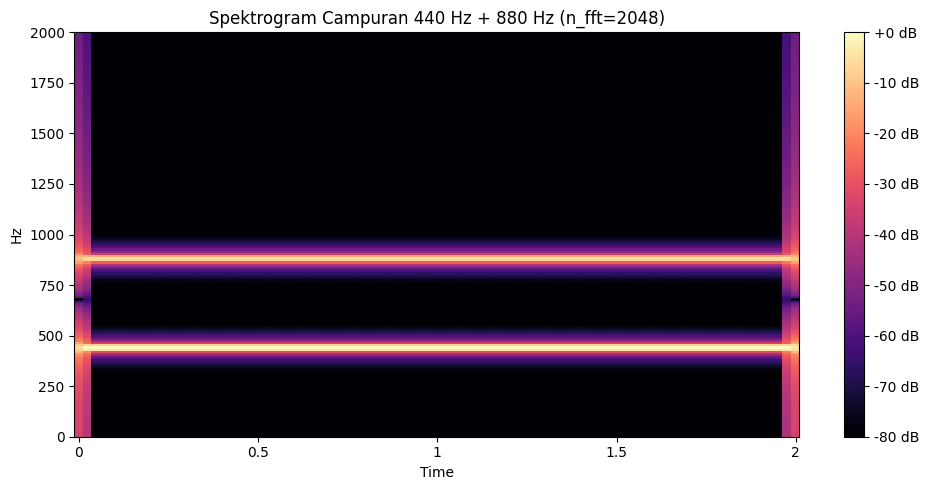

In [11]:
D = librosa.stft(sinyal_campuran, n_fft=2048, hop_length=512)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(10, 5))
librosa.display.specshow(S_db, sr=SR, hop_length=512, x_axis="time", y_axis="hz")
plt.colorbar(format="%+2.0f dB")
plt.ylim(0, 2000)
plt.title("Spektrogram Campuran 440 Hz + 880 Hz (n_fft=2048)")
plt.tight_layout()
plt.show()


### b. Mengulangi STFT dengan `n_fft=512` (jendela pendek) dan `n_fft=4096` (jendela panjang), dibandingkan berdampingan dengan `n_fft=2048`.

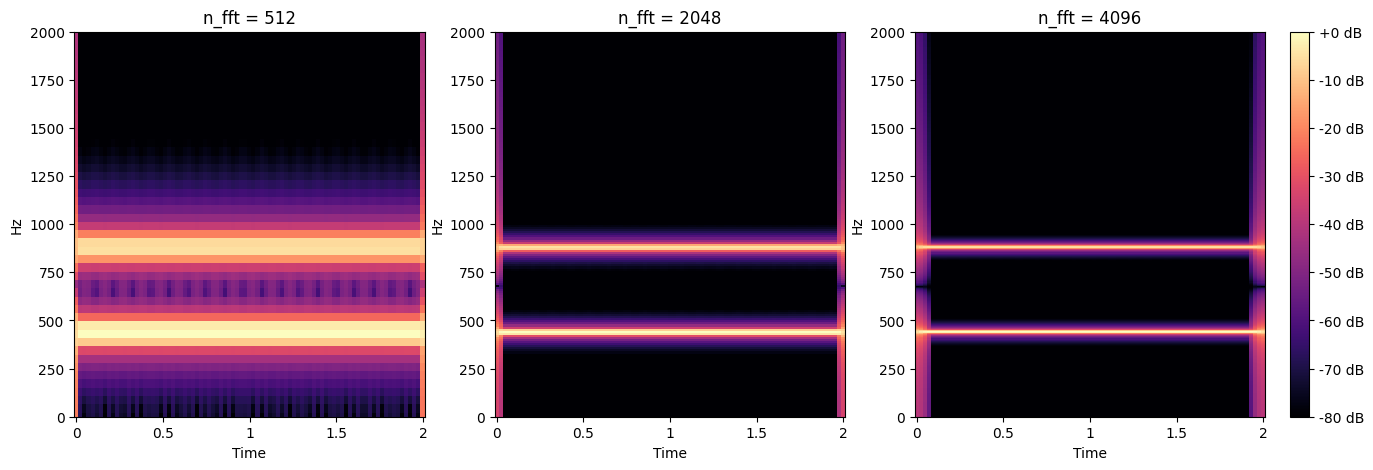

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
img = None
for ax, n_fft in zip(axes, [512, 2048, 4096]):
    D_temp = librosa.stft(sinyal_campuran, n_fft=n_fft, hop_length=512)
    S_db_temp = librosa.amplitude_to_db(np.abs(D_temp), ref=np.max)
    img = librosa.display.specshow(S_db_temp, sr=SR, hop_length=512, x_axis="time", y_axis="hz", ax=ax)
    ax.set_ylim(0, 2000)
    ax.set_title(f"n_fft = {n_fft}")

fig.colorbar(img, ax=axes, format="%+2.0f dB", fraction=0.02, pad=0.02)
plt.show()


### c. Analisis

**Bagaimana spektrogram merepresentasikan dua nada yang bercampur?**

Karena kedua nada berupa gelombang sinus yang tetap sepanjang waktu, pada spektrogram terlihat dua garis horizontal pada frekuensi 440 Hz dan 880 Hz. Intensitas keduanya juga relatif tetap dari awal sampai akhir sinyal. Kedua frekuensi tersebut terlihat terpisah dengan jelas, sehingga spektrogram lebih mudah digunakan untuk melihat masing-masing nada dibandingkan waveform yang hanya menampilkan bentuk sinyal terhadap waktu.

**Apa trade-off antara jendela panjang dan jendela pendek?**

Penggunaan jendela panjang (n_fft=4096) membuat perbedaan frekuensi terlihat lebih jelas, tetapi perubahan yang terjadi terhadap waktu menjadi lebih sulit terlihat. Sebaliknya, jendela pendek (n_fft=512) lebih baik untuk melihat perubahan sinyal yang berlangsung cepat, tetapi frekuensinya terlihat kurang jelas dan pita pada spektrogram menjadi lebih tebal. Jadi, pemilihan nilai n_fft perlu disesuaikan dengan apa yang ingin diamati dari sinyal.

**Mengapa spektrogram 2D lebih cocok diproses CNN dibanding raw waveform 1D?**

CNN bekerja dengan mencari pola pada data menggunakan filter yang bergerak di sepanjang data. Spektrogram sudah menampilkan informasi waktu dan frekuensi dalam bentuk dua dimensi, sehingga pola seperti perubahan nada atau bagian-bagian tertentu dari suara lebih mudah dikenali oleh CNN. Sementara itu, raw waveform masih berupa sinyal mentah dengan jumlah data yang cukup besar dan informasi frekuensinya belum terlihat secara langsung. Karena itu, CNN perlu mempelajari pola frekuensi tersebut dari awal, sehingga prosesnya bisa menjadi lebih sulit dibandingkan menggunakan spektrogram.


## 3. Soal 3 - MFCC

MFCC memadatkan spektrum Mel menjadi vektor koefisien kecil yang menangkap timbre. Alurnya adalah framing menuju STFT menuju filterbank Mel menuju log menuju DCT.

### a. Ekstrak 13 koefisien MFCC dari sinyal campuran menggunakan librosa.feature.mfcc. Tampilkan bentuk (shape) hasil dan visualisasikan.

Bentuk MFCC: (13, 87)  -> (n_mfcc, jumlah_frame)


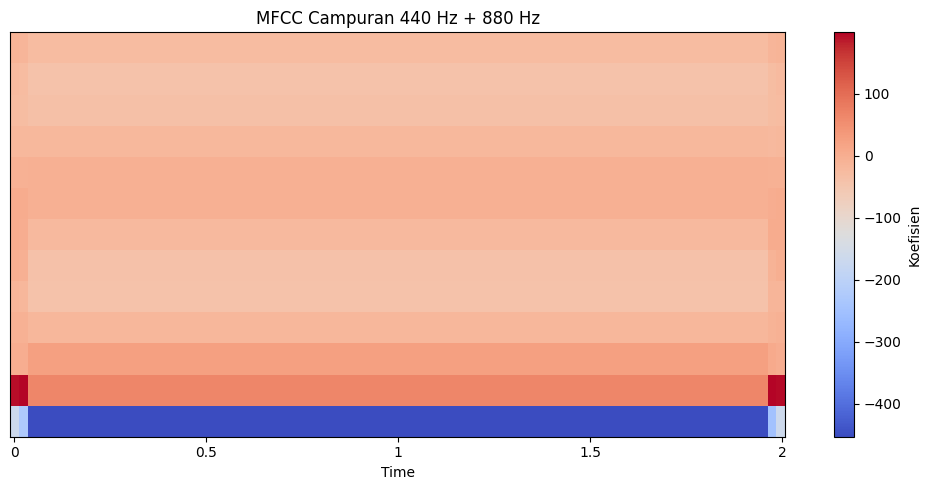

In [13]:
mfcc = librosa.feature.mfcc(y=sinyal_campuran, sr=SR, n_mfcc=13)

print("Bentuk MFCC:", mfcc.shape, " -> (n_mfcc, jumlah_frame)")

plt.figure(figsize=(10, 5))
librosa.display.specshow(mfcc, sr=SR, hop_length=512, x_axis="time")
plt.colorbar(label="Koefisien")
plt.title("MFCC Campuran 440 Hz + 880 Hz")
plt.tight_layout()
plt.show()


### b. Analisis

**Apa arti dimensi pada bentuk (13, N) hasil MFCC?**

Angka 13 menunjukkan jumlah fitur MFCC yang diambil pada setiap bagian waktu dari sinyal. Fitur-fitur ini digunakan untuk menggambarkan karakteristik atau warna suara pada bagian tersebut. Sementara itu, N menunjukkan jumlah bagian waktu yang terbentuk dari keseluruhan sinyal. Jadi, ukuran MFCC 13 x N berarti ada 13 fitur yang digunakan untuk setiap bagian waktu pada sinyal.

**Mengapa MFCC lebih ringkas daripada spektrogram mentah?**

Spektrogram mentah dapat memiliki ratusan hingga ribuan bin frekuensi per bingkai waktu (sebesar n_fft/2 + 1), sedangkan MFCC memampatkan informasi ini melalui filterbank Mel menjadi beberapa puluh pita saja, kemudian menerapkan transformasi DCT yang mendekorelasi dan memusatkan sebagian besar informasi spektral ke koefisien orde rendah. Hasilnya, hanya 13 koefisien sudah cukup menangkap karakteristik timbre yang paling penting, sementara detail berlebih dan kurang relevan secara perseptual dibuang.

**Mengapa filterbank Mel lebih sesuai dengan persepsi pendengaran manusia?**

Skala Mel dibuat untuk menyesuaikan cara manusia mendengar frekuensi. Telinga manusia lebih mudah membedakan perubahan pada frekuensi rendah dibandingkan frekuensi tinggi. Karena itu, MFCC menggunakan skala Mel agar informasi suara yang dianggap lebih penting bagi pendengaran manusia lebih terlihat, sementara informasi yang kurang penting dapat diringkas. Hal ini membuat MFCC lebih praktis digunakan untuk mengenali karakteristik suara atau ucapan.


## 4. Soal 4 - Video sebagai Sekuens Frame

Pendekatan paling sederhana adalah memperlakukan video sebagai urutan frame gambar. Namun pendekatan frame-by-frame mengabaikan informasi temporal (gerakan, urutan, perubahan antar frame).

### a. Membangkitkan "video" sintetis berupa kotak 8x8 yang bergerak horizontal melintasi 24 frame berukuran 48x64.

Bentuk data video: (24, 48, 64)  -> (jumlah_frame, tinggi, lebar)


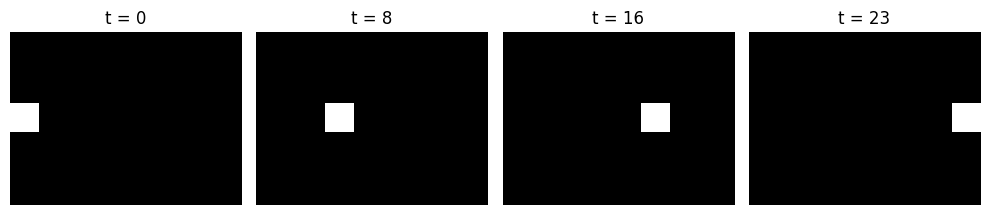

In [14]:
frame_count = 24
h, w = 48, 64
frames = []

for i in range(frame_count):
    frame = np.zeros((h, w), dtype=np.uint8)
    posisi_x = int(i * (w - 8) / (frame_count - 1))
    frame[20:28, posisi_x:posisi_x + 8] = 255
    frames.append(frame)

frames = np.array(frames)
print("Bentuk data video:", frames.shape, " -> (jumlah_frame, tinggi, lebar)")

fig, axes = plt.subplots(1, 4, figsize=(10, 2.5))
for ax, idx in zip(axes, [0, 8, 16, 23]):
    ax.imshow(frames[idx], cmap="gray")
    ax.set_title(f"t = {idx}")
    ax.axis("off")
plt.tight_layout()
plt.show()


### b. Analisis

**Informasi apa yang hilang jika setiap frame diproses CNN 2D secara independen?**

Informasi tentang perubahan dari waktu ke waktu akan hilang, seperti arah gerakan, kecepatan, dan urutan pergerakannya. Jika setiap frame diproses sendiri-sendiri, CNN 2D hanya melihat posisi kotak pada satu frame tanpa mengetahui bagaimana kotak tersebut bergerak dari frame sebelumnya. Akibatnya, model tidak dapat menangkap gerakan dan perubahan yang terjadi dalam video.

**Bagaimana arah dan kecepatan gerakan kotak bisa tertangkap oleh pemodelan temporal?**

Metode seperti 3D CNN, RNN/LSTM, atau optical flow dapat melihat beberapa frame secara berurutan sehingga perubahan posisi objek bisa diketahui. Dari perubahan posisi tersebut, kita bisa melihat seberapa cepat dan ke arah mana objek bergerak. Informasi seperti ini tidak bisa didapat jika setiap frame diproses sendiri, karena model tidak memiliki informasi tentang posisi objek pada frame sebelumnya.

**Mengapa video bukan sekadar "tumpukan gambar"?**

Video memiliki urutan waktu yang bermakna dan hubungan dinamis antar frame yang berurutan (gerakan, sebab-akibat kejadian) yang memberikan makna melebihi sekadar kumpulan gambar statis. Jika urutan frame pada sebuah video diacak, makna kejadian di dalamnya bisa berubah total atau hilang sama sekali, misalnya membedakan adegan pintu dibuka dari pintu ditutup, sedangkan tumpukan gambar independen tidak kehilangan makna apa pun meski urutannya diubah. Perbedaan mendasar inilah yang membuat video memerlukan pemodelan dimensi waktu, bukan sekadar dimensi spasial.


## 5. Soal 5 - Analisis Kritis Pilihan Arsitektur

### a. 3D CNN vs CNN + RNN/LSTM

Konvolusi 3D pada dasarnya merupakan pengembangan dari konvolusi 2D dengan menambahkan dimensi waktu. Dengan begitu, kernel tidak hanya bergerak pada posisi kiri, kanan, atas, dan bawah, tetapi juga mengikuti urutan frame. Hal ini membuat model dapat mengenali pola gerakan yang terjadi dalam beberapa frame sekaligus.

Kelebihan 3D CNN adalah kemampuannya menangkap gerakan secara langsung dan cocok untuk video dengan durasi pendek. Namun, penggunaan kernel pada dimensi waktu membuat kebutuhan parameter dan memori menjadi lebih besar. Selain itu, kemampuan model dalam melihat hubungan antarframe juga masih bergantung pada ukuran kernel yang digunakan.

Sementara itu, 2D CNN + RNN/LSTM membagi proses menjadi dua bagian. CNN digunakan untuk mengambil fitur dari setiap frame, kemudian RNN atau LSTM mempelajari hubungan fitur tersebut dari waktu ke waktu. Karena memiliki memori, RNN/LSTM dapat menyimpan informasi dari frame sebelumnya dan digunakan untuk memahami hubungan yang lebih panjang. Kekurangannya, prosesnya lebih sulit diparalelkan sehingga biasanya membutuhkan waktu lebih lama.

Jadi, 3D CNN lebih cocok untuk menangkap gerakan yang terjadi dalam waktu singkat, sedangkan 2D CNN + RNN/LSTM lebih berguna ketika informasi dari beberapa frame yang berjauhan masih perlu dipertahankan.

### b. Transformer untuk Audio dan Video

Self-attention memungkinkan model melihat hubungan antara semua bagian dalam suatu urutan secara langsung. Jadi, setiap bagian bisa dibandingkan dengan bagian lain tanpa harus memprosesnya satu per satu seperti pada RNN. Hal ini membantu model memahami hubungan yang jaraknya jauh, misalnya hubungan antara awal dan akhir sebuah kalimat pada audio atau hubungan antarobjek dalam video.

Selain itu, self-attention juga dapat diproses secara paralel, sehingga lebih cocok digunakan untuk data dalam jumlah besar. Pada audio, pendekatan ini digunakan pada sistem seperti Whisper untuk mengubah suara menjadi teks. Pada video, salah satu contohnya adalah ViViT yang membagi video menjadi beberapa bagian kecil sebelum mempelajari hubungan antarbagian tersebut.

Namun, self-attention membutuhkan lebih banyak memori dan perhitungan ketika jumlah data semakin besar. Karena itu, untuk audio atau video yang panjang biasanya diperlukan cara tambahan, seperti membagi data menjadi bagian yang lebih kecil atau mengurangi jumlah data yang diproses.

### c. Tantangan Pemrosesan Video

Dua tantangan yang dibahas adalah dimensi tinggi dan ketergantungan jangka panjang.

**Dimensi Tinggi.**
Video memiliki jumlah data yang sangat besar karena terdiri dari ukuran gambar, warna, dan banyak frame. Sebagai contoh, video berukuran 224x224 piksel dengan 3 kanal dan 16 frame saja sudah menghasilkan lebih dari dua juta nilai. Karena itu, pemrosesan video membutuhkan komputasi dan memori yang lebih besar dibandingkan gambar biasa. Untuk mengatasinya, model dapat menggunakan beberapa cara seperti mengurangi jumlah frame yang diproses, membagi proses spasial dan temporal, atau menggunakan patch pada transformer. Selain itu, karena jumlah datanya besar, model juga lebih mudah mengalami overfitting sehingga biasanya membutuhkan data pelatihan yang cukup banyak atau model yang sudah melalui proses pretraining.

**Ketergantungan Jangka Panjang.**
Pada beberapa jenis video, informasi penting tidak selalu muncul dalam waktu yang berdekatan. Contohnya, untuk memahami proses memasak, kita perlu melihat beberapa langkah yang terjadi dari awal sampai akhir. CNN 3D dengan jangkauan waktu yang terbatas bisa kesulitan menangkap hubungan seperti ini. Karena itu, metode seperti LSTM, GRU, atau transformer dapat digunakan untuk melihat hubungan antarframe dalam rentang waktu yang lebih panjang. Namun, semakin banyak bagian video yang diproses, semakin besar juga kebutuhan komputasinya. Salah satu cara untuk mengatasinya adalah dengan mengambil beberapa frame terlebih dahulu, kemudian memproses bagian yang dianggap lebih penting secara lebih detail.